# Лабораторная работа №1: метод обратного распространения ошибки

## Загрузка данных

In [ ]:
import os
import time
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

MNIST_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
MNIST_PATH = "mnist.npz"


def load_mnist(url=MNIST_URL, path=MNIST_PATH):
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    with np.load(path) as data:
        return data["x_train"], data["y_train"], data["x_test"], data["y_test"]


x_train_raw, y_train_raw, x_test_raw, y_test_raw = load_mnist()

print("Обучающая выборка:", len(x_train_raw))
print("Тестовая выборка:", len(x_test_raw))
print("Форма изображения:", x_train_raw[0].shape)
print("Форма меток:", y_train_raw.shape)
print("Классы:", np.unique(y_train_raw))

Обучающая выборка: 60000
Тестовая выборка: 10000
Форма изображения: (28, 28) uint8
Форма меток: (60000,) uint8
Классы: [0 1 2 3 4 5 6 7 8 9]


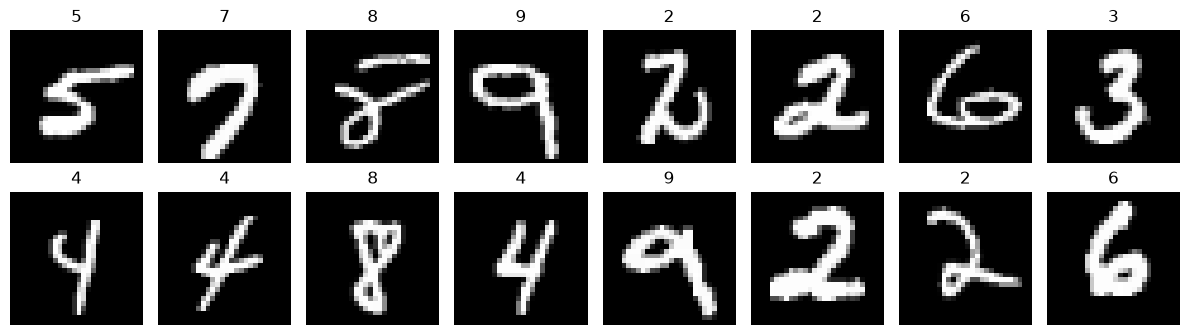

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, np.random.choice(len(x_train_raw), axes.size, replace=False)):
    ax.imshow(x_train_raw[i], cmap="gray")
    ax.set_title(y_train_raw[i])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Предобработка

In [6]:
def preprocess_images(images):
    return images.reshape(len(images), -1).astype(np.float32) / 255.0


def one_hot(labels, num_classes=10):
    encoded = np.zeros((len(labels), num_classes), dtype=np.float32)
    encoded[np.arange(len(labels)), labels] = 1.0
    return encoded


x_train, x_test = preprocess_images(x_train_raw), preprocess_images(x_test_raw)
y_train, y_test = one_hot(y_train_raw), one_hot(y_test_raw)

print("x_train:", x_train.shape, x_train.dtype, f"[{x_train.min()}, {x_train.max()}]")
print("y_train:", y_train.shape, y_train.dtype)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)
print(y_train_raw[-1], "->", y_train[-1])

x_train: (60000, 784) float32 [0.0, 1.0]
y_train: (60000, 10) float32
x_test: (10000, 784)
y_test: (10000, 10)
8 -> [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]


## Нейронная сеть

In [ ]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, seed=0):
        rng = np.random.default_rng(seed)
        self.w1 = (rng.standard_normal((input_size, hidden_size)) * np.sqrt(2.0 / input_size)).astype(np.float32)
        self.b1 = np.zeros(hidden_size, dtype=np.float32)
        self.w2 = (rng.standard_normal((hidden_size, output_size)) * np.sqrt(2.0 / hidden_size)).astype(np.float32)
        self.b2 = np.zeros(output_size, dtype=np.float32)

    def forward(self, x):
        self.x = x
        self.z1 = x @ self.w1 + self.b1
        self.h = np.maximum(self.z1, 0)
        z2 = self.h @ self.w2 + self.b2
        exp = np.exp(z2 - z2.max(axis=1, keepdims=True))
        self.probs = exp / exp.sum(axis=1, keepdims=True)
        return self.probs

    def loss(self, probs, y):
        return -np.mean(np.sum(y * np.log(probs + 1e-12), axis=1))

    def backward(self, y):
        dz2 = (self.probs - y) / len(y)
        self.dw2 = self.h.T @ dz2
        self.db2 = dz2.sum(axis=0)
        dz1 = (dz2 @ self.w2.T) * (self.z1 > 0)
        self.dw1 = self.x.T @ dz1
        self.db1 = dz1.sum(axis=0)

    def step(self, lr):
        self.w1 -= lr * self.dw1
        self.b1 -= lr * self.db1
        self.w2 -= lr * self.dw2
        self.b2 -= lr * self.db2

    def predict(self, x):
        return self.forward(x).argmax(axis=1)

## Обучение

In [13]:
BATCH_SIZE = 32
LEARNING_RATE = 0.1
HIDDEN_SIZE = 300
EPOCHS = 20


def classification_error(model, x, labels):
    return np.mean(model.predict(x) != labels)


model = TwoLayerNet(x_train.shape[1], HIDDEN_SIZE, y_train.shape[1])
rng = np.random.default_rng(0)
history = {"loss": [], "error": []}

for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()
    order = rng.permutation(len(x_train))
    for i in range(0, len(x_train), BATCH_SIZE):
        batch = order[i:i + BATCH_SIZE]
        model.forward(x_train[batch])
        model.backward(y_train[batch])
        model.step(LEARNING_RATE)
    epoch_time = time.perf_counter() - start

    train_loss = model.loss(model.forward(x_train), y_train)
    train_error = classification_error(model, x_train, y_train_raw)
    history["loss"].append(train_loss)
    history["error"].append(train_error)
    print(f"Эпоха {epoch:2d}: loss = {train_loss:.4f}, ошибка на train = {train_error:.4f}, время = {epoch_time:.1f} с")

Эпоха  1: loss = 0.1498, ошибка на train = 0.0414, время = 0.9 с
Эпоха  2: loss = 0.1054, ошибка на train = 0.0302, время = 0.7 с
Эпоха  3: loss = 0.0683, ошибка на train = 0.0188, время = 0.8 с
Эпоха  4: loss = 0.0533, ошибка на train = 0.0142, время = 0.7 с
Эпоха  5: loss = 0.0432, ошибка на train = 0.0113, время = 0.9 с
Эпоха  6: loss = 0.0369, ошибка на train = 0.0100, время = 0.8 с
Эпоха  7: loss = 0.0315, ошибка на train = 0.0072, время = 0.8 с
Эпоха  8: loss = 0.0245, ошибка на train = 0.0053, время = 0.8 с
Эпоха  9: loss = 0.0210, ошибка на train = 0.0039, время = 0.7 с
Эпоха 10: loss = 0.0190, ошибка на train = 0.0037, время = 0.8 с
Эпоха 11: loss = 0.0163, ошибка на train = 0.0025, время = 0.8 с
Эпоха 12: loss = 0.0145, ошибка на train = 0.0020, время = 0.8 с
Эпоха 13: loss = 0.0105, ошибка на train = 0.0012, время = 0.8 с
Эпоха 14: loss = 0.0099, ошибка на train = 0.0012, время = 0.8 с
Эпоха 15: loss = 0.0078, ошибка на train = 0.0005, время = 0.9 с
Эпоха 16: loss = 0.0076, 

## Тестирование

In [14]:
test_loss = model.loss(model.forward(x_test), y_test)
test_error = classification_error(model, x_test, y_test_raw)
print(f"Тест: loss = {test_loss:.4f}, ошибка = {test_error:.4f}, точность = {1 - test_error:.4f}")

Тест: loss = 0.0601, ошибка = 0.0175, точность = 0.9825


## Графики и демонстрация

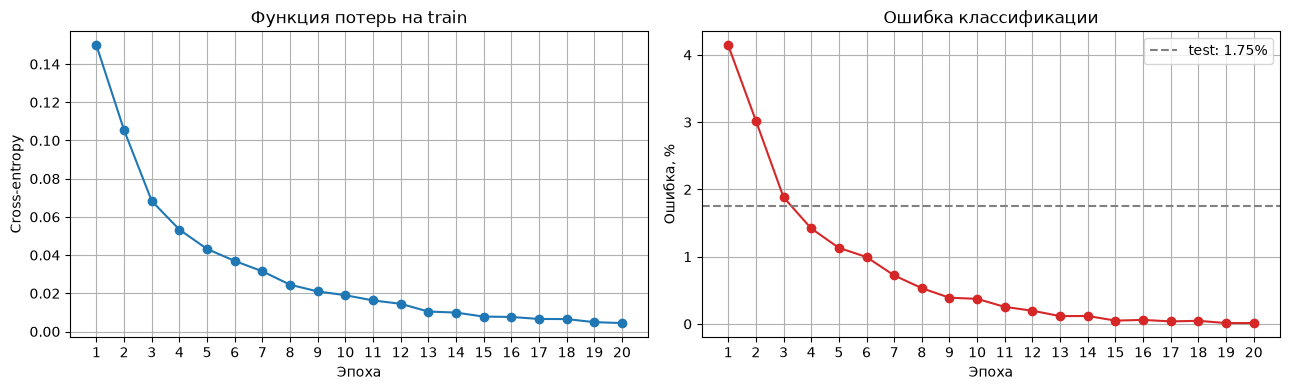

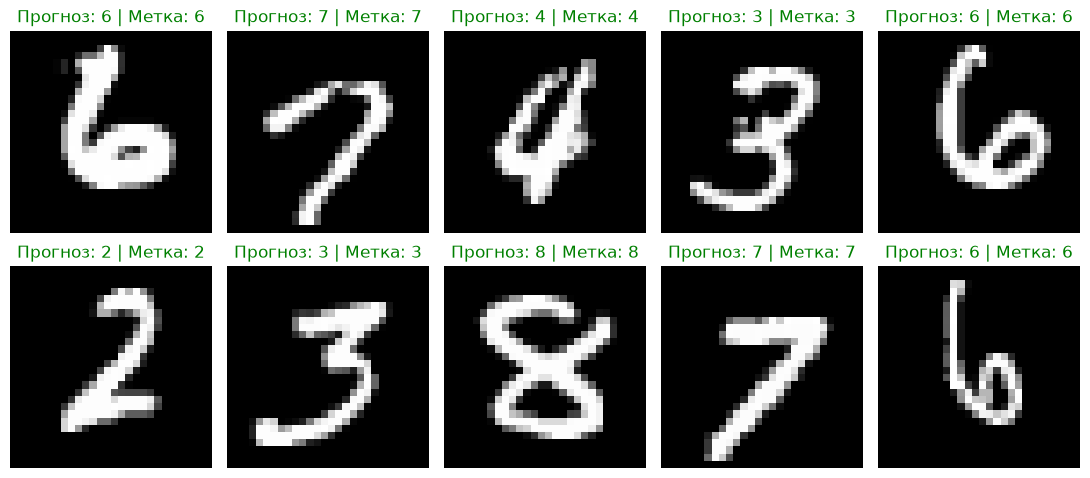

In [15]:
epochs = np.arange(1, len(history["loss"]) + 1)

fig, (ax_loss, ax_error) = plt.subplots(1, 2, figsize=(13, 4))
ax_loss.plot(epochs, history["loss"], marker="o")
ax_loss.set(title="Функция потерь на train", xlabel="Эпоха", ylabel="Cross-entropy")
ax_error.plot(epochs, np.array(history["error"]) * 100, marker="o", color="tab:red")
ax_error.axhline(test_error * 100, linestyle="--", color="gray", label=f"test: {test_error * 100:.2f}%")
ax_error.set(title="Ошибка классификации", xlabel="Эпоха", ylabel="Ошибка, %")
ax_error.legend()
for ax in (ax_loss, ax_error):
    ax.set_xticks(epochs)
    ax.grid(True)
plt.tight_layout()
plt.show()

indices = np.random.choice(len(x_test), 10, replace=False)
predictions = model.predict(x_test[indices])

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, i, pred in zip(axes.flat, indices, predictions):
    ax.imshow(x_test_raw[i], cmap="gray")
    ax.set_title(f"Прогноз: {pred} | Метка: {y_test_raw[i]}", color="green" if pred == y_test_raw[i] else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()